# <b>Task 3.1 - Official Scoring, Sanity Checks, and Basic Validation.</b>

**Goal:** validate baseline filters against the Score metric, compute quality
metrics, and check whether ML classification quality correlates with economic Score.

**Inputs:** `data/enriched/btc_sub10.parquet` (80M rows, all features + PnL pre-computed).

**Structure:**
1. Load data, convert NaN to Null.
2. Unconditional baseline (no filter) - starting point.
3. Random filter - empirical null hypothesis.
4. Threshold baselines per feature - find best single-feature filters.
5. Oracle filter - upper bound.
6. Summary table of all baselines.
7. Classification metrics (precision / recall / F1 / MCC).
8. Correlation: ML quality <-> Score.
9. Limitations of the Score metric.
10. Conclusions.

## <b>Import.</b>

In [1]:
import numpy as np
import polars as pl
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt

import utilities_score as us
import utilities_quality as uq
import utilities_baselines as ub

## <b>Load / Preprocess Data.</b>

In [2]:
# Path to data.
DATA_PATH = r"data/enriched/btc_sub10.parquet"

In [3]:
# Download data.
data = pl.read_parquet(DATA_PATH)

# Convert NaN -> Null in PnL columns for safe polars aggregation.
pnl_cols = [f"pnl_{t}s" for t in us.HORIZONS_S]

data = data.with_columns([
    pl.when(pl.col(c).is_nan()).then(None).otherwise(pl.col(c)).alias(c)
    for c in pnl_cols
])

In [4]:
# Print data statistics.
print(f"Loaded: {data.shape[0]:_} trades from {DATA_PATH}")
print(f"Columns: {data.columns}")
print(f"Null PnL counts:")
for c in pnl_cols:
    print(f"  {c}: {data[c].null_count():,}")

Loaded: 80_403_526 trades from data/enriched/btc_sub10.parquet
Columns: ['timestamp', 'price', 'sign', 'notional', 'weight', 'pnl_30s', 'pnl_120s', 'pnl_300s', 'mid_price', 'spread', 'obi', 'dist_to_mid', 'hour', 'vpin_5s', 'vpin_30s', 'vpin_120s', 'rv_5s', 'rv_30s', 'rv_120s', 'liq_binance_5s', 'liq_binance_30s', 'liq_binance_120s', 'liq_bybit_5s', 'liq_bybit_30s', 'liq_bybit_120s']
Null PnL counts:
  pnl_30s: 30
  pnl_120s: 108
  pnl_300s: 413


## <b>1. Unconditional baseline (no filter).</b>

Score = 0 by definition: PnL_kept = PnL_all when nothing is filtered.

This is starting point - every filter is measured as improvement over this.

In [5]:
# calculation.
f_none          = ub.no_filter(data.shape[0])
results_none    = us.compute_score_all_horizons(data, f_none)
data_baseline   = us.score_summary_df(results_none)

# results.
print("Unconditional baseline (no filter):")
display(data_baseline)

Unconditional baseline (no filter):


horizon,PnL_all (bps),PnL_kept (bps),PnL_filtered (bps),Score (bps),filter_rate (%),kept_usd/day,turnover_ok
str,f64,f64,f64,f64,f64,f64,i64
"""30s""",-0.106879,-0.106879,0.0,0.0,0.0,1.2238e9,1
"""120s""",-0.040558,-0.040558,0.0,0.0,0.0,1.2238e9,1
"""300s""",0.007218,0.007218,0.0,0.0,0.0,1.2238e9,1


## <b>2. Random filter - null hypothesis.</b>

A random filter should produce Score ~= 0. We run 100 realizations at 30% filter rate and plot the empirical distribution of Score(30s). 

Any useful filter must beat this.

Random 10%: Score_30s=+0.0017 bps, filter=10.0%, turnover_ok=True
Random 30%: Score_30s=+0.0007 bps, filter=30.0%, turnover_ok=True
Random 50%: Score_30s=+0.0030 bps, filter=50.0%, turnover_ok=True

Random 30% ensemble (100 runs):


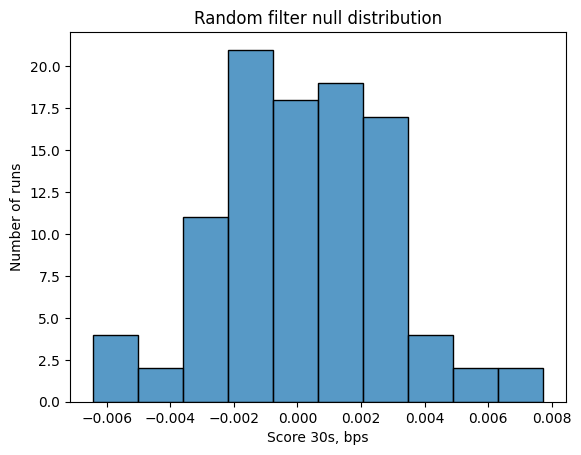

  Mean Score_30s:  +0.000214 bps
  Std  Score_30s:  0.002690 bps
  Max  Score_30s:  +0.007745 bps
  Min  Score_30s:  -0.006448 bps
  95th percentile: +0.004313 bps

A useful filter must beat ~+0.0043 bps (95th pct of random)


In [6]:
# single realizations at different rates.
for rate in [0.1, 0.3, 0.5]:
    f_rand  = ub.random_filter(data.shape[0], rate, seed=42)
    r       = us.compute_score(data, f_rand, tau=30)
    print(f"Random {rate:.0%}: Score_30s={r.score:+.4f} bps, filter={r.filter_rate:.1%}, turnover_ok={r.turnover_ok}")


# ensemble: 100 realizations at 30%.
print("\nRandom 30% ensemble (100 runs):")
ensemble = ub.random_filter_ensemble(data.shape[0], filter_rate=0.3, n_runs=100)
scores_null = []
for f_r in ensemble:
    r = us.compute_score(data, f_r, tau=30)
    scores_null.append(r.score)
scores_null = np.array(scores_null)


# plot distribution.
plt.figure()
sns.histplot(scores_null, bins=10)
plt.title("Random filter null distribution")
plt.xlabel("Score 30s, bps")
plt.ylabel("Number of runs")
plt.show()

# Statistics.
print(f"  Mean Score_30s:  {scores_null.mean():+.6f} bps")
print(f"  Std  Score_30s:  {scores_null.std():.6f} bps")
print(f"  Max  Score_30s:  {scores_null.max():+.6f} bps")
print(f"  Min  Score_30s:  {scores_null.min():+.6f} bps")
print(f"  95th percentile: {np.percentile(scores_null, 95):+.6f} bps")
print(f"\nA useful filter must beat ~{np.percentile(scores_null, 95):+.4f} bps (95th pct of random)")

## <b>3. Threshold baselines per feature.</b>

For each feature scan thresholds at quantiles (10%, 20%, ..., 90%), compute Score at all horizons, and find the best threshold.

Features and expected filtering direction:
- **VPIN** (above): high VPIN = high toxicity -> filter.
- **dist_to_mid** (below): low dist_to_mid = aggressive sell below mid.
- **OBI** (below): ask-heavy = potential downward pressure -> filter.
- **spread** (above): wide spread can be toxic in moderate range.
- **rv_30s** (above): high volatility.
- **liq_binance_30s + liq_bybit_30s** (above): high liquidation activity.
- **hour**: specific toxic hours (22 UTC).

In [7]:
# define features.
FEATURE_CONFIGS = [
    ("vpin_5s",         "above",  "VPIN 5s (high = toxic)"),
    ("vpin_30s",        "above",  "VPIN 30s (high = toxic)"),
    ("vpin_120s",       "above",  "VPIN 120s"),
    ("dist_to_mid",     "above",  "Dist-to-mid (above = aggres. buy)"),
    ("dist_to_mid",     "below",  "Dist-to-mid (below = aggres. sell)"),
    ("obi",             "below",  "OBI (ask-heavy)"),
    ("obi",             "above",  "OBI (bid-heavy)"),
    ("spread",          "above",  "Spread (wide)"),
    ("rv_5s",           "above",  "RV 5s (high vol)"),
    ("rv_30s",          "above",  "RV 30s (high vol)"),
    ("rv_120s",         "above",  "RV 120s (high vol)"),
    ("liq_binance_5s",  "above",  "Liq Binance 5s"),
    ("liq_binance_30s", "above",  "Liq Binance 30s"),
    ("liq_binance_120s","above",  "Liq Binance 120s"),
    ("liq_bybit_30s",   "above",  "Liq Bybit 30s")
]

In [8]:
# scan all features.
best_baselines = {}

for col_name, direction, label in FEATURE_CONFIGS:
    values  = ub.get_feature_array(data, col_name)
    scans   = ub.scan_thresholds(values, direction=direction)

    best_score = -999
    best_entry = None

    for q, thresh, f_arr in scans:
        r = us.compute_score(data, f_arr, tau=30)

        if r.turnover_ok and r.score > best_score:
            best_score = r.score
            best_entry = (q, thresh, f_arr, r)

    if best_entry is not None:
        q, thresh, f_arr, r = best_entry
        print(
            f"{label:<35s}  | best q={q:.0%}, thresh={thresh:>10.4f} | "
            f"Score_30={r.score:+.4f} bps | filter={r.filter_rate:.1%} | "
            f"turnover={r.kept_turnover_per_day:,.0f}"
        )
        results_all = us.compute_score_all_horizons(data, f_arr)
        best_baselines[label] = (results_all, f_arr)
    else:
        print(f"{label:<35s} | no valid threshold (turnover constraint)")


# hour filter.
for toxic_hours in [[22], [22, 23], [21, 22, 23]]:

    hours   = data["hour"].to_numpy().astype(np.int8)
    f_hour  = ub.hour_filter(hours, toxic_hours)
    r       = us.compute_score(data, f_hour, tau=30)
    label   = f"Hour filter {toxic_hours}"

    if r.turnover_ok:
        print(
            f"{label:<35s}  | "
            f"Score_30={r.score:+.4f} bps | filter={r.filter_rate:.1%} | "
            f"turnover={r.kept_turnover_per_day:,.0f}"
        )

        results_all = us.compute_score_all_horizons(data, f_hour)
        best_baselines[label] = (results_all, f_hour)

VPIN 5s (high = toxic)               | best q=70%, thresh=    0.6997 | Score_30=+0.0368 bps | filter=30.0% | turnover=836,089,032
VPIN 30s (high = toxic)              | best q=90%, thresh=    0.6501 | Score_30=-0.0081 bps | filter=10.0% | turnover=1,076,458,590
VPIN 120s                            | best q=90%, thresh=    0.4660 | Score_30=-0.0289 bps | filter=10.0% | turnover=1,071,807,756
Dist-to-mid (above = aggres. buy)    | best q=10%, thresh=   -0.6800 | Score_30=+0.6468 bps | filter=90.0% | turnover=139,474,286
Dist-to-mid (below = aggres. sell)   | best q=90%, thresh=    0.6693 | Score_30=+0.0331 bps | filter=90.0% | turnover=136,394,489
OBI (ask-heavy)                      | best q=90%, thresh=    0.9933 | Score_30=+0.0589 bps | filter=90.0% | turnover=59,643,686
OBI (bid-heavy)                      | best q=10%, thresh=    0.0066 | Score_30=+0.0043 bps | filter=90.0% | turnover=60,047,663
Spread (wide)                        | best q=10%, thresh=    0.1000 | Score_30=-0.0290 

## <b>4. Oracle filter (look-ahead).</b>

Filters trades with `pnl < 0`. 

Uses future information - this is the **theoretical upper bound** on Score. 

Any real filter scoring above this has a bug.

In [9]:
oracle_baselines = {}
for tau in us.HORIZONS_S:
    pnl     = ub.get_pnl_array(data, tau)
    f_orc   = ub.oracle_filter(pnl)
    results = us.compute_score_all_horizons(data, f_orc)
    label   = f"Oracle (pnl_{tau}s < 0)"
    oracle_baselines[label] = (results, f_orc)

    r = us.compute_score(data, f_orc, tau)
    print(
        f"  {label}: Score_{tau}s={r.score:+.4f} bps, "
        f"filter={r.filter_rate:.1%}, turnover={r.kept_turnover_per_day:_.0f}"
    )

print("\nNote: real filters must be below this.")

  Oracle (pnl_30s < 0): Score_30s=+5.9865 bps, filter=50.7%, turnover=615_714_988
  Oracle (pnl_120s < 0): Score_120s=+10.9968 bps, filter=50.1%, turnover=616_932_806
  Oracle (pnl_300s < 0): Score_300s=+16.4157 bps, filter=50.0%, turnover=616_887_385

Note: real filters must be below this.


## <b>5. Summary table of all baselines.</b>

In [10]:
# collect all results into one table.
rows = []

# no filter.
for r in results_none:
    rows.append({"filter": "No filter", "horizon": f"{r.tau}s",
                 "Score_bps": r.score, "PnL_kept": r.pnl_kept,
                 "PnL_filtered": r.pnl_filtered, "filter_%": r.filter_rate * 100,
                 "turnover_ok": r.turnover_ok})

# random 30%.
f_rand30 = ub.random_filter(data.shape[0], 0.3, seed=42)
for r in us.compute_score_all_horizons(data, f_rand30):
    rows.append({"filter": "Random 30%", "horizon": f"{r.tau}s",
                 "Score_bps": r.score, "PnL_kept": r.pnl_kept,
                 "PnL_filtered": r.pnl_filtered, "filter_%": r.filter_rate * 100,
                 "turnover_ok": r.turnover_ok})

# threshold baselines.
for label, (results_all, _) in best_baselines.items():
    for r in results_all:
        rows.append({"filter": label, "horizon": f"{r.tau}s",
                     "Score_bps": r.score, "PnL_kept": r.pnl_kept,
                     "PnL_filtered": r.pnl_filtered, "filter_%": r.filter_rate * 100,
                     "turnover_ok": r.turnover_ok})

# oracle (use pnl_30s oracle for summary).
for label, (results_all, _) in oracle_baselines.items():
    for r in results_all:
        rows.append({"filter": label, "horizon": f"{r.tau}s",
                     "Score_bps": r.score, "PnL_kept": r.pnl_kept,
                     "PnL_filtered": r.pnl_filtered, "filter_%": r.filter_rate * 100,
                     "turnover_ok": r.turnover_ok})

df_summary = pl.DataFrame(rows)

# show 30s horizon for compact view.
df_30s = (
    df_summary
    .filter(pl.col("horizon") == "30s")
    .sort("Score_bps", descending=True)
)
print("All baselines — Score at 30s horizon (sorted by Score):")
display(df_30s)

# show all horizons for top-5 filters.
top5_names = df_30s.head(5)["filter"].to_list()
print("\nTop-5 filters — all horizons:")
display(
    df_summary
    .filter(pl.col("filter").is_in(top5_names))
    .sort(["filter", "horizon"])
)

All baselines — Score at 30s horizon (sorted by Score):


filter,horizon,Score_bps,PnL_kept,PnL_filtered,filter_%,turnover_ok
str,str,f64,f64,f64,f64,i64
"""Oracle (pnl_30s < 0)""","""30s""",5.986493,5.879613,-6.168647,50.66,1
"""Oracle (pnl_120s < 0)""","""30s""",3.296353,3.189474,-3.457971,50.13,1
"""Oracle (pnl_300s < 0)""","""30s""",2.243189,2.13631,-2.386955,49.99,1
"""Dist-to-mid (above = aggres. b…","""30s""",0.646817,0.539938,-0.190079,90.0,1
"""Liq Binance 30s""","""30s""",0.506531,0.399652,-0.179363,90.0,1
…,…,…,…,…,…,…
"""VPIN 120s""","""30s""",-0.02892,-0.1358,0.097081,10.0,1
"""Spread (wide)""","""30s""",-0.029025,-0.135904,0.251404,7.27,1
"""RV 120s (high vol)""","""30s""",-0.043502,-0.150381,0.220232,10.0,1



Top-5 filters — all horizons:


filter,horizon,Score_bps,PnL_kept,PnL_filtered,filter_%,turnover_ok
str,str,f64,f64,f64,f64,i64
"""Dist-to-mid (above = aggres. b…","""120s""",0.881733,0.841174,-0.153975,90.0,1
"""Dist-to-mid (above = aggres. b…","""300s""",0.936913,0.94413,-0.113298,90.0,1
"""Dist-to-mid (above = aggres. b…","""30s""",0.646817,0.539938,-0.190079,90.0,1
"""Liq Binance 30s""","""120s""",0.527842,0.487283,-0.116092,90.0,1
"""Liq Binance 30s""","""300s""",0.553696,0.560914,-0.072016,90.0,1
…,…,…,…,…,…,…
"""Oracle (pnl_300s < 0)""","""300s""",16.415743,16.42296,-16.678317,49.99,1
"""Oracle (pnl_300s < 0)""","""30s""",2.243189,2.13631,-2.386955,49.99,1
"""Oracle (pnl_30s < 0)""","""120s""",5.86229,5.821732,-5.976572,50.66,1


## <b>6. Classification metrics.</b>

Each filter viewed as a binary classifier predicting "toxic trade" (`pnl_30s < 0`).

Metrics weighted by `w_i` (trade weight) to align with Score.

In [11]:
# ground truth and weights.
pnl_30  = ub.get_pnl_array(data, 30)
w       = data["weight"].to_numpy().astype(np.float64)


# collect all filters for classification evaluation.
all_filters = {}
all_filters["No filter"]    = ub.no_filter(data.shape[0])
all_filters["Random 30%"]   = ub.random_filter(data.shape[0], 0.3, seed=42)
for label, (_, f_arr) in best_baselines.items(): all_filters[label] = f_arr
# add only the oracle that matches the classification target.
for label, (_, f_arr) in oracle_baselines.items(): 
    if "pnl_30s" in label: all_filters[label] = f_arr


# compute classification metrics.
cls_metrics = []
for name, f_arr in all_filters.items():
    m = uq.compute_classification_metrics(f_arr, pnl_30, w, name=name)
    cls_metrics.append(m)


# show results.
df_cls = pl.DataFrame(uq.classification_metrics_table(cls_metrics))
print("Classification metrics (weighted, pnl_30s < 0 as toxic):")
display(df_cls.sort("MCC", descending=True))

Classification metrics (weighted, pnl_30s < 0 as toxic):


filter,precision,recall,F1,MCC,filter_%,toxic_%
str,f64,f64,f64,f64,f64,f64
"""Oracle (pnl_30s < 0)""",1.0,1.0,1.0,1.0,49.69,49.69
"""Dist-to-mid (above = aggres. b…",0.499906,0.891434,0.640581,0.016898,88.6,49.69
"""Dist-to-mid (below = aggres. s…",0.499625,0.893463,0.640874,0.015526,88.85,49.69
"""Liq Bybit 30s""",0.499177,0.875125,0.63573,0.011964,87.11,49.69
"""Liq Binance 30s""",0.49876,0.878131,0.636182,0.009959,87.48,49.69
…,…,…,…,…,…,…
"""VPIN 30s (high = toxic)""",0.48596,0.11774,0.189555,-0.008077,12.04,49.69
"""Liq Binance 5s""",0.481198,0.098284,0.163229,-0.010538,10.15,49.69
"""RV 30s (high vol)""",0.481784,0.119169,0.191076,-0.011299,12.29,49.69


## <b>7. Correlation: ML quality <-> Score.</b>

Central question: does a better classifier (higher F1/MCC) produce higher Score?

Expected finding: **positive correlation, but not perfect**.

Score depends on the magnitude of PnL, not just its sign.

A filter that catches the 1000 most negative trades (large magnitude) may score higher than one that catches 5000 slightly negative trades.

In [12]:
# exclude oracle and no-filter (they are definitional extremes).
# also exclude filters that fail turnover constraint.
filter_names_for_corr = []
f1_vals = []
mcc_vals = []
score_vals = []

for m in cls_metrics:
    if "Oracle" in m.name or "No filter" in m.name:
        continue
    # find corresponding Score.
    match = df_summary.filter(
        (pl.col("filter") == m.name) & (pl.col("horizon") == "30s")
    )
    if 0 == match.height:
        continue
    s = match[0, "Score_bps"]
    if s is None or np.isnan(s):
        continue

    filter_names_for_corr.append(m.name)
    f1_vals.append(m.f1_weighted)
    mcc_vals.append(m.mcc_weighted)
    score_vals.append(s)

f1_arr  = np.array(f1_vals)
mcc_arr = np.array(mcc_vals)
sc_arr  = np.array(score_vals)

# F1 vs Score.
corr_f1 = uq.compute_quality_score_correlation(f1_arr, sc_arr)
print("F1 vs Score(30s):")
print(f"  Pearson r  = {corr_f1['pearson_r']:+.4f}  (p={corr_f1['pearson_p']:.4f})")
print(f"  Spearman rho = {corr_f1['spearman_rho']:+.4f}  (p={corr_f1['spearman_p']:.4f})")

# MCC vs Score.
corr_mcc = uq.compute_quality_score_correlation(mcc_arr, sc_arr)
print("\nMCC vs Score(30s):")
print(f"  Pearson r  = {corr_mcc['pearson_r']:+.4f}  (p={corr_mcc['pearson_p']:.4f})")
print(f"  Spearman rho = {corr_mcc['spearman_rho']:+.4f}  (p={corr_mcc['spearman_p']:.4f})")

# Print the data points.
print(f"\n{'Filter':<35s} {'F1':>8} {'MCC':>8} {'Score_30':>10}")
print("-" * 65)
for name, f1, mcc, sc in zip(filter_names_for_corr, f1_vals, mcc_vals, score_vals):
    print(f"{name:<35s} {f1:>8.4f} {mcc:>8.4f} {sc:>+10.4f}")

F1 vs Score(30s):
  Pearson r  = +0.6668  (p=0.0018)
  Spearman rho = +0.5053  (p=0.0273)

MCC vs Score(30s):
  Pearson r  = +0.6689  (p=0.0017)
  Spearman rho = +0.8649  (p=0.0000)

Filter                                    F1      MCC   Score_30
-----------------------------------------------------------------
Random 30%                            0.3740  -0.0002    +0.0007
VPIN 5s (high = toxic)                0.3875   0.0011    +0.0368
VPIN 30s (high = toxic)               0.1896  -0.0081    -0.0081
VPIN 120s                             0.1916  -0.0134    -0.0289
Dist-to-mid (above = aggres. buy)     0.6406   0.0169    +0.6468
Dist-to-mid (below = aggres. sell)    0.6409   0.0155    +0.0331
OBI (ask-heavy)                       0.6529   0.0010    +0.0589
OBI (bid-heavy)                       0.6525  -0.0015    +0.0043
Spread (wide)                         0.1274  -0.0061    -0.0290
RV 5s (high vol)                      0.1980  -0.0147    -0.0708
RV 30s (high vol)                   